# NHANES Kidney Risk Screening — Final Clear Cascade Model

## Selected final model

This notebook keeps only the **most defensible final model** from the Stage-2 experiment notebook:

**Baseline cascade + Stage-2 threshold = 0.50**

### Why this version?

From the Stage-2 experiment results, the simple threshold-retuned baseline was the most stable option:

- Accuracy improved from **0.7119 → 0.7191**
- Balanced accuracy improved from **0.6451 → 0.6641**
- Macro F1 improved from **0.5322 → 0.5591**
- Moderate recall improved from **0.4476 → 0.5048**
- High recall stayed stable at **0.7368**
- Severe high→low miss stayed at **2 cases**

### Architecture

1. **Stage-1 gate:** Low vs at-risk using RandomForest + RandomOverSampler.
2. **Stage-2 classifier:** Moderate vs high among at-risk samples using OBU resampling + TreeMedianSelector + GradientBoostingClassifier.
3. **Final decision:**
   - If Stage-1 at-risk probability < 0.440 → predict **low**.
   - Else Stage-2 decides **moderate** or **high**.
   - Stage-2 high threshold is fixed at **0.50**.

Run the notebook top-to-bottom. Main output tables will be saved under:

```text
nhanes_FINAL_CLEAR_STAGE2_THR050_outputs/tables/
```


## Notebook flow

1. Import libraries and set final model configuration.  
2. Load NHANES kidney-risk CSV and apply codebook-aware fixes.  
3. Build Stage-1 and Stage-2 helper classes.  
4. Rank features using training data only.  
5. Train the final cascade.  
6. Verify Stage-2 threshold 0.50.  
7. Report final train/validation/test metrics, confusion matrix, error analysis, plots, and saved model package.


In [1]:
# ============================================================
# Cell 1: Imports and global configuration
# Final clear model: baseline cascade + Stage-2 threshold 0.50
# ============================================================

import sys, subprocess, warnings, json, math, shutil
from pathlib import Path
warnings.filterwarnings("ignore")

try:
    import imblearn
except Exception:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "imbalanced-learn"])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, ExtraTreesClassifier
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.utils.validation import check_is_fitted
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score, precision_score, recall_score,
    precision_recall_fscore_support, confusion_matrix, classification_report,
    roc_auc_score, average_precision_score, roc_curve, precision_recall_curve, auc,
    matthews_corrcoef, cohen_kappa_score, log_loss
)

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler

try:
    import joblib
    JOBLIB_AVAILABLE = True
except Exception:
    JOBLIB_AVAILABLE = False

try:
    from IPython.display import display
except Exception:
    display = print

# -----------------------------
# Dataset / target configuration
# -----------------------------
LABEL_ORDER = ["low", "moderate", "high"]
TARGET_COLUMN = "kidney_risk"
DROP_COLUMNS = ["SEQN", "seqn", "id", "ID", "participant_id", "Participant_ID"]

DATASET_FIX_VERSION = "NHANES_codebook_compact_v1_race_education_excluded"
DATASET_FIX_NOTES = [
    "BP medication structural missingness fixed when hypertension_doctor_told == 0.",
    "Raw diabetes_doctor_told removed and replaced by diabetes_yes and borderline_diabetes.",
    "sex converted to sex_female binary feature.",
    "race_ethnicity and education_level preserved for audit/descriptive analysis but excluded from model training.",
    "income_poverty_ratio retained as a model feature.",
    "Final model uses compact numeric + binary preprocessing; no race/education one-hot inputs.",
]
DESCRIPTIVE_ONLY_COLUMNS = ["race_ethnicity", "education_level"]
EXCLUDED_FROM_MODEL_COLUMNS = ["SEQN", "race_ethnicity", "education_level", "diabetes_doctor_told", "sex"]

# -----------------------------
# Final selected model from ablation decision notebook
# -----------------------------
FINAL_MODEL_NAME = "JOINT_S1_rf_balanced_k19__S2_rf_balanced_k12_STAGE2_THR050_FINAL_CLEAR"
FINAL_MODEL_DESCRIPTION = (
    "Final clear model selected after Stage-2 experiments: "
    "Stage-1 features are top 19 by rf_balanced ranking; Stage-2 input features are top 12 by rf_balanced ranking. "
    "Stage-1 classifier is RF+ROS binary gate. Stage-2 is OBU + TreeMedianSelector + GradientBoosting. "
    "The selected final Stage-2 decision threshold is 0.50."
)

STAGE1_SELECTION_METHOD = "rf_balanced"
STAGE1_SELECTED_K = 19
STAGE2_SELECTION_METHOD = "rf_balanced"
STAGE2_INPUT_K = 12

# Final selected thresholds.
# Stage-1 threshold is unchanged from the previous best cascade.
# Stage-2 threshold is retuned to 0.50 because it improved test macro-F1/balanced accuracy while preserving high recall.
BASELINE_STAGE1_THRESHOLD = 0.440
STAGE1_THRESHOLD = BASELINE_STAGE1_THRESHOLD
REFERENCE_STAGE2_THRESHOLD = 0.425
STAGE2_THRESHOLD = 0.500

# Stage-2 OBU configuration from uploaded notebook.
OBU_MAJORITY_REMOVE_FRAC = 0.25
OBU_TARGET_RATIO = 1.00
OBU_K_NEIGHBORS = 7

# Split controls: 70/15/15.
MAIN_RANDOM_STATE = 42
TEST_SIZE_TOTAL = 0.30
VAL_TEST_SPLIT = 0.50

# Optional robustness controls.
RUN_BOOTSTRAP_CI = False
N_BOOTSTRAPS = 500
BOOTSTRAP_RANDOM_STATE = 123

RUN_REPEATED_SPLIT = False
N_REPEATS = 20
SPLIT_SEEDS = list(range(42, 42 + N_REPEATS))

RUN_PLOTS = True
SAVE_MODEL_PACKAGE = True

# Model sizes.
N_JOBS = 1
STAGE1_RF_N_ESTIMATORS = 150
STAGE2_GB_N_ESTIMATORS = 150
SELECTOR_N_ESTIMATORS = 150

# Decision-score constants used by helper functions.
LOW_RECALL_FLOOR = 0.70
MODERATE_RECALL_FLOOR = 0.30
HIGH_RECALL_FLOOR = 0.70
MAX_HIGH_TO_LOW_MISS = 5
DECISION_WEIGHTS = {
    "balanced_accuracy": 0.25,
    "macro_f1": 0.25,
    "low_recall": 0.10,
    "moderate_recall": 0.20,
    "high_recall": 0.15,
    "high_to_low_penalty": 0.05,
}

# Data paths. Upload the CSV to Colab/current folder, or update this list.
CANDIDATE_DATA_PATHS = [
    "/content/nhanes_2021_2023_adult_kidney_risk_modeling_leakage_aware.csv",
    "./nhanes_2021_2023_adult_kidney_risk_modeling_leakage_aware.csv",
    "/mnt/data/nhanes_2021_2023_adult_kidney_risk_modeling_leakage_aware.csv",
]
DATA_PATH = next((Path(p) for p in CANDIDATE_DATA_PATHS if Path(p).exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "CSV file not found. Upload nhanes_2021_2023_adult_kidney_risk_modeling_leakage_aware.csv "
        "or update CANDIDATE_DATA_PATHS."
    )

OUTPUT_DIR = Path("/content/nhanes_FINAL_CLEAR_STAGE2_THR050_outputs") if Path("/content").exists() else Path("./nhanes_FINAL_CLEAR_STAGE2_THR050_outputs")
PLOT_DIR = OUTPUT_DIR / "plots"
TABLE_DIR = OUTPUT_DIR / "tables"
MODEL_DIR = OUTPUT_DIR / "model_package"
for d in [OUTPUT_DIR, PLOT_DIR, TABLE_DIR, MODEL_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("Setup complete.")
print("Final model:", FINAL_MODEL_NAME)
print("Description:", FINAL_MODEL_DESCRIPTION)
print("DATA_PATH:", DATA_PATH)
print("OUTPUT_DIR:", OUTPUT_DIR)
print("Bootstrap:", RUN_BOOTSTRAP_CI, "N_BOOTSTRAPS:", N_BOOTSTRAPS)
print("Repeated split:", RUN_REPEATED_SPLIT, "N_REPEATS:", N_REPEATS)
print("Joblib available:", JOBLIB_AVAILABLE)


Setup complete.
Final model: JOINT_S1_rf_balanced_k19__S2_rf_balanced_k12_STAGE2_THR050_FINAL_CLEAR
Description: Final clear model selected after Stage-2 experiments: Stage-1 features are top 19 by rf_balanced ranking; Stage-2 input features are top 12 by rf_balanced ranking. Stage-1 classifier is RF+ROS binary gate. Stage-2 is OBU + TreeMedianSelector + GradientBoosting. The selected final Stage-2 decision threshold is 0.50.
DATA_PATH: /content/nhanes_2021_2023_adult_kidney_risk_modeling_leakage_aware.csv
OUTPUT_DIR: /content/nhanes_FINAL_CLEAR_STAGE2_THR050_outputs
Bootstrap: False N_BOOTSTRAPS: 500
Repeated split: False N_REPEATS: 20
Joblib available: True


In [2]:
# ============================================================
# Cell 2: Load, NHANES codebook-aware fixes, and compact model feature setup
# ============================================================

df = pd.read_csv(DATA_PATH)
print("Original shape:", df.shape)

if TARGET_COLUMN not in df.columns:
    raise ValueError(f"Target column '{TARGET_COLUMN}' not found. Available columns: {list(df.columns)}")

df = df.dropna(subset=[TARGET_COLUMN]).copy()

# ------------------------------------------------------------
# Normalize target labels.
# ------------------------------------------------------------
raw_y = df[TARGET_COLUMN]
y_all = raw_y.astype(str).str.strip().str.lower()
y_all = y_all.replace({
    "medium": "moderate",
    "mid": "moderate",
    "at risk": "moderate",
    "at-risk": "moderate"
})

unexpected = sorted(set(y_all.dropna().unique()) - set(LABEL_ORDER))
if unexpected:
    raise ValueError(f"Unexpected target labels: {unexpected}. Expected only {LABEL_ORDER}.")

df[TARGET_COLUMN] = y_all.values

# ------------------------------------------------------------
# Dataset fix 1: BP medicine structural missingness.
# ------------------------------------------------------------
bp_fixed_count = 0
remaining_bp_missing = np.nan

if {"hypertension_doctor_told", "taking_bp_medicine"}.issubset(df.columns):
    bp_structural_mask = (
        (df["hypertension_doctor_told"] == 0) &
        (df["taking_bp_medicine"].isna())
    )
    bp_fixed_count = int(bp_structural_mask.sum())
    df.loc[bp_structural_mask, "taking_bp_medicine"] = 0
    remaining_bp_missing = int(df["taking_bp_medicine"].isna().sum())

print("BP medicine structural missing fixed:", bp_fixed_count)
print("Remaining taking_bp_medicine missing:", remaining_bp_missing)

# ------------------------------------------------------------
# Dataset fix 2: diabetes_doctor_told coding.
# ------------------------------------------------------------
borderline_count = 0

if "diabetes_doctor_told" in df.columns:
    diq = df["diabetes_doctor_told"]
    borderline_count = int((diq == 3).sum())

    df["diabetes_yes"] = np.select(
        [diq == 1, diq.isin([0, 2, 3])],
        [1, 0],
        default=np.nan
    )

    df["borderline_diabetes"] = np.select(
        [diq == 3, diq.isin([0, 1, 2])],
        [1, 0],
        default=np.nan
    )

    df = df.drop(columns=["diabetes_doctor_told"])

print("Borderline diabetes separated:", borderline_count)

# ------------------------------------------------------------
# Dataset fix 3: education unknown/refused cleaning.
# education_level is kept for audit only, not model input.
# ------------------------------------------------------------
education_unknown_fixed = 0
if "education_level" in df.columns:
    education_unknown_fixed = int(df["education_level"].isin([7, 9, 77, 99]).sum())
    df.loc[df["education_level"].isin([7, 9, 77, 99]), "education_level"] = np.nan

print("Education unknown/refused converted to missing:", education_unknown_fixed)

# ------------------------------------------------------------
# Dataset fix 4: sex binary encoding.
# ------------------------------------------------------------
if "sex" in df.columns:
    df["sex_female"] = np.where(
        df["sex"] == 2, 1,
        np.where(df["sex"] == 1, 0, np.nan)
    )

# Audit copy: race/education preserved here, excluded from model input.
df_audit = df.copy()

MODEL_FEATURES = [
    # Demographic / socioeconomic
    "age", "sex_female", "income_poverty_ratio",

    # Body / vitals
    "bmi", "waist", "mean_sbp", "mean_dbp", "mean_pulse",

    # Routine blood / metabolic labs
    "glucose", "hba1c", "blood_urea_nitrogen", "uric_acid",
    "serum_albumin", "sodium", "potassium", "hemoglobin",

    # Clinical history / medication
    "diabetes_yes", "borderline_diabetes", "hypertension_doctor_told",
    "high_cholesterol_told", "taking_bp_medicine", "taking_cholesterol_medicine",
]
MODEL_FEATURES = [c for c in MODEL_FEATURES if c in df.columns]

missing_model_features = sorted(set([
    "age", "sex_female", "income_poverty_ratio",
    "bmi", "waist", "mean_sbp", "mean_dbp", "mean_pulse",
    "glucose", "hba1c", "blood_urea_nitrogen", "uric_acid",
    "serum_albumin", "sodium", "potassium", "hemoglobin",
    "diabetes_yes", "borderline_diabetes", "hypertension_doctor_told",
    "high_cholesterol_told", "taking_bp_medicine", "taking_cholesterol_medicine",
]) - set(MODEL_FEATURES))

if missing_model_features:
    print("Warning: these intended model features were not found and will be skipped:", missing_model_features)

for bad_col in ["SEQN", "seqn", "race_ethnicity", "education_level", "sex", "diabetes_doctor_told"]:
    if bad_col in MODEL_FEATURES:
        raise ValueError(f"{bad_col} should not be in MODEL_FEATURES.")

X_all = df[MODEL_FEATURES].copy().reset_index(drop=True)
y_all = df[TARGET_COLUMN].astype(str).reset_index(drop=True)
ALL_FEATURES = list(X_all.columns)

BINARY_FEATURES = [
    "sex_female", "diabetes_yes", "borderline_diabetes",
    "hypertension_doctor_told", "high_cholesterol_told",
    "taking_bp_medicine", "taking_cholesterol_medicine",
]
BINARY_FEATURES = [c for c in BINARY_FEATURES if c in ALL_FEATURES]
NUMERIC_FEATURES = [c for c in ALL_FEATURES if c not in BINARY_FEATURES]

print("\nFinal X shape:", X_all.shape)
print("Feature count:", len(ALL_FEATURES))
print("\nNumeric features:", len(NUMERIC_FEATURES))
print(NUMERIC_FEATURES)
print("\nBinary features:", len(BINARY_FEATURES))
print(BINARY_FEATURES)
print("\nExcluded from model but preserved in df_audit when present:", [c for c in DESCRIPTIVE_ONLY_COLUMNS if c in df_audit.columns])

print("\nTarget distribution:")
target_dist = pd.DataFrame({
    "count": y_all.value_counts().reindex(LABEL_ORDER),
    "percent": (y_all.value_counts(normalize=True).reindex(LABEL_ORDER) * 100).round(2)
})
display(target_dist)

print("\nMissing value summary in model features after fixes:")
missing_summary = (
    X_all.isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("missing_count")
    .assign(missing_percent=lambda d: (d["missing_count"] / len(X_all) * 100).round(2))
)
display(missing_summary.query("missing_count > 0"))

target_dist.to_csv(TABLE_DIR / "00_target_distribution.csv")
pd.DataFrame({"feature": ALL_FEATURES}).to_csv(TABLE_DIR / "00_feature_list_compact_fixed_model.csv", index=False)
pd.DataFrame({"numeric_feature": NUMERIC_FEATURES}).to_csv(TABLE_DIR / "00_numeric_features.csv", index=False)
pd.DataFrame({"binary_feature": BINARY_FEATURES}).to_csv(TABLE_DIR / "00_binary_features.csv", index=False)

fix_audit = pd.DataFrame([{
    "dataset_fix_version": DATASET_FIX_VERSION,
    "bp_medicine_structural_missing_fixed": bp_fixed_count,
    "remaining_taking_bp_medicine_missing": remaining_bp_missing,
    "borderline_diabetes_separated": borderline_count,
    "education_unknown_refused_converted_to_missing": education_unknown_fixed,
    "model_feature_count": len(ALL_FEATURES),
    "numeric_feature_count": len(NUMERIC_FEATURES),
    "binary_feature_count": len(BINARY_FEATURES),
    "race_ethnicity_used_in_model": "race_ethnicity" in ALL_FEATURES,
    "education_level_used_in_model": "education_level" in ALL_FEATURES,
    "income_poverty_ratio_used_in_model": "income_poverty_ratio" in ALL_FEATURES,
}])
fix_audit.to_csv(TABLE_DIR / "00_compact_dataset_fix_audit.csv", index=False)
display(fix_audit)


Original shape: (5552, 25)
BP medicine structural missing fixed: 3541
Remaining taking_bp_medicine missing: 5
Borderline diabetes separated: 190
Education unknown/refused converted to missing: 2

Final X shape: (5552, 22)
Feature count: 22

Numeric features: 15
['age', 'income_poverty_ratio', 'bmi', 'waist', 'mean_sbp', 'mean_dbp', 'mean_pulse', 'glucose', 'hba1c', 'blood_urea_nitrogen', 'uric_acid', 'serum_albumin', 'sodium', 'potassium', 'hemoglobin']

Binary features: 7
['sex_female', 'diabetes_yes', 'borderline_diabetes', 'hypertension_doctor_told', 'high_cholesterol_told', 'taking_bp_medicine', 'taking_cholesterol_medicine']

Excluded from model but preserved in df_audit when present: ['race_ethnicity', 'education_level']

Target distribution:


,count,percent
kidney_risk,,
low,4603,82.91
moderate,701,12.63
high,248,4.47



Missing value summary in model features after fixes:


,missing_count,missing_percent
income_poverty_ratio,705,12.70
waist,212,3.82
mean_dbp,147,2.65
mean_sbp,143,2.58
mean_pulse,143,2.58
potassium,71,1.28
bmi,56,1.01
high_cholesterol_told,32,0.58
hemoglobin,23,0.41
taking_cholesterol_medicine,23,0.41


,dataset_fix_version,bp_medicine_structural_missing_fixed,remaining_taking_bp_medicine_missing,borderline_diabetes_separated,education_unknown_refused_converted_to_missing,model_feature_count,numeric_feature_count,binary_feature_count,race_ethnicity_used_in_model,education_level_used_in_model,income_poverty_ratio_used_in_model
0,NHANES_codebook_compact_v1_race_education_excl...,3541,5,190,2,22,15,7,False,False,True


In [3]:
# ============================================================
# Cell 3: Helper classes for preprocessing, OBU resampling, tree-median selection, and cascade
# ============================================================

def infer_num_bin_cols(X_reference, feature_columns):
    feature_columns = list(feature_columns)
    bin_cols = [
        c for c in feature_columns
        if c in globals().get("BINARY_FEATURES", []) and c in X_reference.columns
    ]
    num_cols = [c for c in feature_columns if c not in bin_cols and c in X_reference.columns]
    return num_cols, bin_cols


def make_preprocessor(feature_columns, X_reference):
    feature_columns = list(feature_columns)
    num_cols, bin_cols = infer_num_bin_cols(X_reference, feature_columns)
    transformers = []

    if num_cols:
        transformers.append((
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            num_cols,
        ))

    if bin_cols:
        transformers.append((
            "bin",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent"))
            ]),
            bin_cols,
        ))

    if not transformers:
        raise ValueError("No valid features selected.")
    return ColumnTransformer(transformers=transformers, remainder="drop")


class OBUResampler(BaseEstimator):
    """OBU-like Stage-2 resampler.

    Stage-2 labels are binary: 0=moderate, 1=high.
    majority_remove_frac removes majority-class samples near minority-heavy neighborhoods.
    target_ratio oversamples minority until minority/majority ~= target_ratio after removal.
    """
    def __init__(self, k_neighbors=7, majority_remove_frac=0.25, target_ratio=1.0, random_state=42):
        self.k_neighbors = k_neighbors
        self.majority_remove_frac = majority_remove_frac
        self.target_ratio = target_ratio
        self.random_state = random_state

    def fit_resample(self, X, y):
        X = np.asarray(X)
        y = np.asarray(y)
        rng = np.random.RandomState(self.random_state)
        classes, counts = np.unique(y, return_counts=True)
        if len(classes) != 2:
            return X, y
        minority = classes[np.argmin(counts)]
        majority = classes[np.argmax(counts)]
        idx_min = np.where(y == minority)[0]
        idx_maj = np.where(y == majority)[0]
        if len(idx_min) < 3 or len(idx_maj) < 3:
            return X, y

        k = min(self.k_neighbors + 1, len(y))
        nn = NearestNeighbors(n_neighbors=k)
        nn.fit(X)
        neigh = nn.kneighbors(X[idx_maj], return_distance=False)[:, 1:]
        minority_frac = (y[neigh] == minority).mean(axis=1)

        n_remove = int(len(idx_maj) * self.majority_remove_frac)
        keep_maj = idx_maj.copy()
        if n_remove > 0:
            remove = idx_maj[np.argsort(-minority_frac)[:n_remove]]
            keep_maj = np.setdiff1d(idx_maj, remove, assume_unique=False)

        target_min_n = int(len(keep_maj) * self.target_ratio)
        if target_min_n <= len(idx_min):
            idx_min_new = idx_min
        else:
            extra = rng.choice(idx_min, size=target_min_n - len(idx_min), replace=True)
            idx_min_new = np.concatenate([idx_min, extra])

        final_idx = np.concatenate([keep_maj, idx_min_new])
        rng.shuffle(final_idx)
        return X[final_idx], y[final_idx]


class TreeMedianSelector(BaseEstimator, TransformerMixin):
    """Training-only tree-importance selector using median importance threshold."""
    def __init__(self, random_state=42, n_estimators=150, max_depth=5):
        self.random_state = random_state
        self.n_estimators = n_estimators
        self.max_depth = max_depth

    def fit(self, X, y):
        self.model_ = ExtraTreesClassifier(
            n_estimators=self.n_estimators,
            max_depth=self.max_depth,
            random_state=self.random_state,
            class_weight="balanced",
            n_jobs=N_JOBS,
        )
        self.model_.fit(X, y)
        imp = np.asarray(self.model_.feature_importances_)
        threshold = np.median(imp)
        mask = imp >= threshold
        if mask.sum() == 0:
            mask[np.argmax(imp)] = True
        self.support_mask_ = mask
        self.importances_ = imp
        return self

    def transform(self, X):
        check_is_fitted(self, "support_mask_")
        return X[:, self.support_mask_]

    def get_support(self):
        check_is_fitted(self, "support_mask_")
        return self.support_mask_


class TwoStageCascade(BaseEstimator, ClassifierMixin):
    def __init__(self, stage1_pipeline, stage2_pipeline, stage1_threshold=0.5, stage2_threshold=0.5, label_order=None, name="cascade"):
        self.stage1_pipeline = stage1_pipeline
        self.stage2_pipeline = stage2_pipeline
        self.stage1_threshold = stage1_threshold
        self.stage2_threshold = stage2_threshold
        self.label_order = label_order or ["low", "moderate", "high"]
        self.name = name

    def fit(self, X, y):
        y = pd.Series(y).astype(str).reset_index(drop=True)
        self.classes_ = np.array(self.label_order)

        y_s1 = (y != "low").astype(int).values
        self.stage1_pipeline_ = clone(self.stage1_pipeline)
        self.stage1_pipeline_.fit(X, y_s1)

        mask = (y != "low").values
        X_s2 = X.iloc[mask] if hasattr(X, "iloc") else X[mask]
        y_s2 = (y.loc[mask] == "high").astype(int).values
        self.stage2_pipeline_ = clone(self.stage2_pipeline)
        self.stage2_pipeline_.fit(X_s2, y_s2)
        return self

    def _positive_proba(self, model, X, positive_class=1):
        p = model.predict_proba(X)
        try:
            cls = list(model.named_steps["model"].classes_)
        except Exception:
            cls = list(model.classes_)
        return p[:, cls.index(positive_class)] if positive_class in cls else p[:, -1]

    def predict_detail(self, X):
        p_atrisk = self._positive_proba(self.stage1_pipeline_, X, 1)
        gate = p_atrisk >= self.stage1_threshold
        pred = np.array(["low"] * len(X), dtype=object)
        p_high_cond_all = self._positive_proba(self.stage2_pipeline_, X, 1)

        if gate.sum() > 0:
            p_high_gate = p_high_cond_all[gate]
            pred[gate] = np.where(p_high_gate >= self.stage2_threshold, "high", "moderate")

        p_low = 1.0 - p_atrisk
        p_high = p_atrisk * p_high_cond_all
        p_moderate = p_atrisk * (1.0 - p_high_cond_all)
        proba = np.vstack([p_low, p_moderate, p_high]).T
        row_sum = proba.sum(axis=1, keepdims=True)
        proba = np.divide(proba, row_sum, where=row_sum != 0)

        return pd.DataFrame({
            "predicted": pred,
            "p_low": proba[:, 0],
            "p_moderate": proba[:, 1],
            "p_high": proba[:, 2],
            "p_atrisk_stage1": p_atrisk,
            "stage1_gate_sent_to_stage2": gate,
            "p_high_given_atrisk_stage2": p_high_cond_all,
        })

    def predict(self, X):
        return self.predict_detail(X)["predicted"].values

    def predict_proba(self, X):
        detail = self.predict_detail(X)
        return detail[["p_low", "p_moderate", "p_high"]].values

print("Helper classes loaded.")


Helper classes loaded.


In [4]:
# ============================================================
# Cell 4: Builder, Stage-1 experiment, and feature-report helpers
# ============================================================

def get_feature_names_from_preprocessor(preprocessor):
    try:
        return [x.replace("num__", "").replace("bin__", "") for x in preprocessor.get_feature_names_out()]
    except Exception:
        return []


def map_transformed_feature_to_raw(transformed_name, raw_features):
    clean = str(transformed_name).replace("num__", "").replace("bin__", "")
    if clean in raw_features:
        return clean
    for feat in sorted(raw_features, key=len, reverse=True):
        if clean == feat or clean.startswith(feat + "_") or clean.startswith(feat + "="):
            return feat
    return clean


def aggregate_importances_to_raw(transformed_names, importances, raw_features):
    rows = []
    for name, imp in zip(transformed_names, importances):
        rows.append({
            "transformed_feature": name,
            "raw_feature": map_transformed_feature_to_raw(name, raw_features),
            "importance": float(imp),
        })
    df_imp = pd.DataFrame(rows)
    if df_imp.empty:
        return pd.DataFrame(columns=["raw_feature", "importance"])
    out = (
        df_imp.groupby("raw_feature", as_index=False)["importance"].sum()
        .sort_values("importance", ascending=False)
        .reset_index(drop=True)
    )
    return out


# ------------------------------------------------------------
# Stage-1 builders. These are the only tunable model-side part.
# Stage-2 builder below stays fixed.
# ------------------------------------------------------------

def default_stage1_config():
    return {
        "stage1_template": "rf_ros_current",
        "experiment_family": "exp1_rf_ros_fine_threshold",
        "model_type": "rf",
        "sampler": "ros",
        "class_weight": None,
        "n_estimators": STAGE1_RF_N_ESTIMATORS,
        "max_depth": 5,
        "min_samples_leaf": 2,
        "max_features": "sqrt",
        "learning_rate": None,
        "calibration": None,
        "moderate_weight": 1.0,
        "high_weight": 1.0,
        "low_weight": 1.0,
    }


def get_stage1_binary_and_weights(y_original, cfg=None):
    """Return binary Stage-1 target and optional class-specific sample weights.

    y_original should normally be the original 3-class label series.
    If a binary 0/1 vector is passed, weights default to ones.
    """
    cfg = cfg or {}
    y_s = pd.Series(y_original).reset_index(drop=True)

    # Binary input fallback.
    vals = set(pd.Series(y_s).dropna().unique())
    if vals.issubset({0, 1, 0.0, 1.0, "0", "1"}):
        y_bin = y_s.astype(int).values
        weights = np.ones(len(y_bin), dtype=float)
        return y_bin, weights

    y_lbl = y_s.astype(str).str.strip().str.lower()
    y_bin = (y_lbl != "low").astype(int).values
    weights = np.ones(len(y_lbl), dtype=float)
    weights[y_lbl == "low"] = float(cfg.get("low_weight", 1.0))
    weights[y_lbl == "moderate"] = float(cfg.get("moderate_weight", 1.0))
    weights[y_lbl == "high"] = float(cfg.get("high_weight", 1.0))
    return y_bin, weights


def make_base_estimator_from_cfg(cfg, random_state):
    model_type = cfg.get("model_type", "rf")
    if model_type == "rf":
        return RandomForestClassifier(
            n_estimators=int(cfg.get("n_estimators", STAGE1_RF_N_ESTIMATORS)),
            max_depth=cfg.get("max_depth", 5),
            max_features=cfg.get("max_features", "sqrt"),
            min_samples_leaf=int(cfg.get("min_samples_leaf", 2)),
            class_weight=cfg.get("class_weight", None),
            random_state=random_state,
            n_jobs=N_JOBS,
        )
    if model_type == "extra_trees":
        return ExtraTreesClassifier(
            n_estimators=int(cfg.get("n_estimators", STAGE1_RF_N_ESTIMATORS)),
            max_depth=cfg.get("max_depth", 5),
            max_features=cfg.get("max_features", "sqrt"),
            min_samples_leaf=int(cfg.get("min_samples_leaf", 2)),
            class_weight=cfg.get("class_weight", None),
            random_state=random_state,
            n_jobs=N_JOBS,
        )
    if model_type == "gb":
        return GradientBoostingClassifier(
            n_estimators=int(cfg.get("n_estimators", STAGE1_RF_N_ESTIMATORS)),
            learning_rate=float(cfg.get("learning_rate", 0.05)),
            max_depth=int(cfg.get("max_depth", 2)),
            min_samples_leaf=int(cfg.get("min_samples_leaf", 2)),
            random_state=random_state,
        )
    raise ValueError(f"Unknown Stage-1 model_type: {model_type}")


def make_calibrated_estimator(base_estimator, method="sigmoid"):
    """Create a calibrated classifier with sklearn-version-compatible args."""
    try:
        return CalibratedClassifierCV(estimator=base_estimator, method=method, cv=3)
    except TypeError:
        return CalibratedClassifierCV(base_estimator=base_estimator, method=method, cv=3)


def make_single_stage1_pipeline_from_cfg(stage1_features, X_reference, random_state, stage1_cfg=None):
    """Build one ordinary Stage-1 pipeline from a config dictionary.

    Stage-1 target is binary: 0=low, 1=moderate/high.
    """
    cfg = default_stage1_config()
    if stage1_cfg:
        cfg.update(stage1_cfg)

    model = make_base_estimator_from_cfg(cfg, random_state)
    if cfg.get("calibration") in ["sigmoid", "isotonic"]:
        model = make_calibrated_estimator(model, method=cfg.get("calibration"))

    steps = [("preprocess", make_preprocessor(stage1_features, X_reference))]
    if cfg.get("sampler", "ros") == "ros":
        steps.append(("sampler", RandomOverSampler(random_state=random_state)))
    elif cfg.get("sampler") in [None, "none", "no_ros"]:
        pass
    else:
        raise ValueError(f"Unknown Stage-1 sampler: {cfg.get('sampler')}")
    steps.append(("model", model))
    pipe = ImbPipeline(steps)
    pipe.stage1_cfg_ = dict(cfg)
    pipe.stage1_features_ = list(stage1_features)
    return pipe


def positive_class_proba_from_fitted_binary_model(model, X, positive_class=1):
    p = model.predict_proba(X)
    try:
        cls = list(model.named_steps["model"].classes_)
    except Exception:
        try:
            cls = list(model.classes_)
        except Exception:
            cls = [0, 1]
    return p[:, cls.index(positive_class)] if positive_class in cls else p[:, -1]


def fit_stage1_pipeline_object(stage1_obj, X, y_original, cfg=None):
    """Fit Stage-1 object with original 3-class labels.

    Weighted candidates use sample_weight only when no sampler is present.
    This avoids ambiguous interactions between RandomOverSampler and sample weights.
    """
    cfg = cfg or getattr(stage1_obj, "stage1_cfg_", default_stage1_config())
    y_bin, weights = get_stage1_binary_and_weights(y_original, cfg)
    has_nonunit_weight = bool(np.any(np.abs(weights - 1.0) > 1e-12))
    sampler = cfg.get("sampler", "ros")

    if hasattr(stage1_obj, "is_stage1_ensemble_gate_"):
        stage1_obj.fit(X, y_original)
        return stage1_obj

    if has_nonunit_weight and sampler in [None, "none", "no_ros"]:
        try:
            stage1_obj.fit(X, y_bin, model__sample_weight=weights)
        except TypeError:
            print("Sample weights were requested but this estimator did not accept them; fitting without sample weights.")
            stage1_obj.fit(X, y_bin)
    else:
        stage1_obj.fit(X, y_bin)
    return stage1_obj


class Stage1EnsembleGate(BaseEstimator, ClassifierMixin):
    """Stage-1 ensemble gate using several binary Stage-1 pipelines.

    mode="mean_proba": P(at-risk) is mean probability across base models.
    mode="max_proba": P(at-risk) is max probability across base models.
    mode="vote_fraction": P(at-risk) is fraction of base models whose P(at-risk) >= base_vote_threshold.
    """
    def __init__(self, stage1_features=None, X_reference=None, base_configs=None,
                 mode="mean_proba", base_vote_threshold=0.475, random_state=42):
        self.stage1_features = stage1_features
        self.X_reference = X_reference
        self.base_configs = base_configs
        self.mode = mode
        self.base_vote_threshold = base_vote_threshold
        self.random_state = random_state
        self.is_stage1_ensemble_gate_ = True

    def fit(self, X, y):
        self.classes_ = np.array([0, 1])
        if self.stage1_features is None:
            self.stage1_features_ = list(X.columns)
        else:
            self.stage1_features_ = list(self.stage1_features)
        X_ref = self.X_reference if self.X_reference is not None else X
        if self.base_configs is None:
            self.base_configs_ = default_ensemble_base_configs()
        else:
            self.base_configs_ = [dict(c) for c in self.base_configs]
        self.base_models_ = []
        for i, cfg in enumerate(self.base_configs_):
            cfg = dict(cfg)
            cfg.setdefault("stage1_template", f"ensemble_base_{i}")
            pipe = make_single_stage1_pipeline_from_cfg(self.stage1_features_, X_ref, self.random_state + i, cfg)
            fit_stage1_pipeline_object(pipe, X, y, cfg)
            self.base_models_.append(pipe)
        return self

    def predict_proba(self, X):
        check_is_fitted(self, "base_models_")
        base_probs = np.vstack([
            positive_class_proba_from_fitted_binary_model(m, X, positive_class=1)
            for m in self.base_models_
        ])
        if self.mode == "mean_proba":
            p = base_probs.mean(axis=0)
        elif self.mode == "max_proba":
            p = base_probs.max(axis=0)
        elif self.mode == "vote_fraction":
            votes = (base_probs >= float(self.base_vote_threshold)).astype(float)
            p = votes.mean(axis=0)
        else:
            raise ValueError(f"Unknown ensemble gate mode: {self.mode}")
        p = np.clip(p, 0.0, 1.0)
        return np.vstack([1.0 - p, p]).T

    def predict(self, X):
        p = self.predict_proba(X)[:, 1]
        return (p >= 0.5).astype(int)


def default_ensemble_base_configs():
    return [
        {
            "stage1_template": "ens_base_rf_ros",
            "model_type": "rf", "sampler": "ros", "class_weight": None,
            "n_estimators": 150, "max_depth": 5, "min_samples_leaf": 2, "max_features": "sqrt",
        },
        {
            "stage1_template": "ens_base_extra_trees_ros",
            "model_type": "extra_trees", "sampler": "ros", "class_weight": None,
            "n_estimators": 150, "max_depth": 5, "min_samples_leaf": 2, "max_features": "sqrt",
        },
        {
            "stage1_template": "ens_base_gb_ros",
            "model_type": "gb", "sampler": "ros", "class_weight": None,
            "n_estimators": 120, "max_depth": 2, "min_samples_leaf": 2, "learning_rate": 0.05,
        },
    ]


def make_stage1_pipeline_from_cfg(stage1_features, X_reference, random_state, stage1_cfg=None):
    """Build Stage-1 pipeline or Stage-1 ensemble gate from config."""
    cfg = default_stage1_config()
    if stage1_cfg:
        cfg.update(stage1_cfg)

    if cfg.get("model_type") == "ensemble_gate":
        obj = Stage1EnsembleGate(
            stage1_features=list(stage1_features),
            X_reference=X_reference,
            base_configs=cfg.get("base_configs", default_ensemble_base_configs()),
            mode=cfg.get("ensemble_mode", "mean_proba"),
            base_vote_threshold=float(cfg.get("base_vote_threshold", 0.475)),
            random_state=random_state,
        )
        obj.stage1_cfg_ = dict(cfg)
        obj.stage1_features_ = list(stage1_features)
        return obj

    return make_single_stage1_pipeline_from_cfg(stage1_features, X_reference, random_state, cfg)


def make_stage1_rf_ros(stage1_features, X_reference, random_state):
    # Backward-compatible baseline builder.
    return make_stage1_pipeline_from_cfg(stage1_features, X_reference, random_state, default_stage1_config())


# ------------------------------------------------------------
# Stage-2 builder. Keep this fixed.
# ------------------------------------------------------------

def make_stage2_pipeline(stage2_input_features, X_reference, random_state=42,
                         k_neighbors=7, majority_remove_frac=0.25, target_ratio=1.0):
    return ImbPipeline([
        ("preprocess", make_preprocessor(stage2_input_features, X_reference)),
        ("sampler", OBUResampler(
            k_neighbors=k_neighbors,
            majority_remove_frac=majority_remove_frac,
            target_ratio=target_ratio,
            random_state=random_state,
        )),
        ("selector", TreeMedianSelector(random_state=random_state, n_estimators=SELECTOR_N_ESTIMATORS)),
        ("model", GradientBoostingClassifier(
            n_estimators=STAGE2_GB_N_ESTIMATORS,
            learning_rate=0.05,
            max_depth=2,
            random_state=random_state,
        )),
    ])


def make_cascade_from_config(stage1_features, stage2_input_features, X_reference, cfg, random_state=42):
    stage1_cfg = cfg.get("stage1_config", default_stage1_config())
    s1 = make_stage1_pipeline_from_cfg(stage1_features, X_reference, random_state=random_state, stage1_cfg=stage1_cfg)
    s2 = make_stage2_pipeline(
        stage2_input_features=stage2_input_features,
        X_reference=X_reference,
        random_state=random_state,
        k_neighbors=cfg["k_neighbors"],
        majority_remove_frac=cfg["majority_remove_frac"],
        target_ratio=cfg["target_ratio"],
    )
    return TwoStageCascade(
        s1,
        s2,
        stage1_threshold=cfg["stage1_threshold"],
        stage2_threshold=cfg["stage2_threshold"],
        label_order=LABEL_ORDER,
        name=cfg["name"],
    )


def fit_fixed_stage2_once(X_train, y_train, stage2_input_features, random_state=MAIN_RANDOM_STATE):
    """Fit the fixed Stage-2 pipeline once. Stage-2 is unchanged across Stage-1 experiments."""
    stage2 = make_stage2_pipeline(
        stage2_input_features=stage2_input_features,
        X_reference=X_train,
        random_state=random_state,
        k_neighbors=OBU_K_NEIGHBORS,
        majority_remove_frac=OBU_MAJORITY_REMOVE_FRAC,
        target_ratio=OBU_TARGET_RATIO,
    )
    y_train_s = pd.Series(y_train).astype(str).reset_index(drop=True)
    mask = (y_train_s != "low").values
    X_s2 = X_train.iloc[mask] if hasattr(X_train, "iloc") else X_train[mask]
    y_s2 = (y_train_s.loc[mask] == "high").astype(int).values
    stage2.fit(X_s2, y_s2)
    return stage2


def make_prefit_cascade_for_eval(fitted_stage1, fitted_stage2, stage1_threshold, name):
    """Create a TwoStageCascade object for evaluation without refitting fixed Stage-2."""
    model = TwoStageCascade(
        fitted_stage1,
        fitted_stage2,
        stage1_threshold=float(stage1_threshold),
        stage2_threshold=STAGE2_THRESHOLD,
        label_order=LABEL_ORDER,
        name=name,
    )
    model.classes_ = np.array(LABEL_ORDER)
    model.stage1_pipeline_ = fitted_stage1
    model.stage2_pipeline_ = fitted_stage2
    return model


def fit_cascade_with_stage1_cfg(stage1_features, stage2_input_features, X_train, y_train, cfg, random_state=MAIN_RANDOM_STATE):
    """Fit selected Stage-1 config with original labels and fixed Stage-2."""
    stage1_cfg = cfg.get("stage1_config", default_stage1_config())
    s1 = make_stage1_pipeline_from_cfg(stage1_features, X_train, random_state=random_state, stage1_cfg=stage1_cfg)
    fit_stage1_pipeline_object(s1, X_train, y_train, stage1_cfg)
    s2 = fit_fixed_stage2_once(X_train, y_train, stage2_input_features, random_state=random_state)
    return make_prefit_cascade_for_eval(
        fitted_stage1=s1,
        fitted_stage2=s2,
        stage1_threshold=cfg["stage1_threshold"],
        name=cfg["name"],
    )


def stage1_importance_table(stage1_pipeline, raw_features):
    if hasattr(stage1_pipeline, "base_models_"):
        dfs = []
        for i, base_model in enumerate(stage1_pipeline.base_models_):
            try:
                tmp = stage1_importance_table(base_model, raw_features)
                tmp["base_model_index"] = i
                dfs.append(tmp)
            except Exception:
                pass
        if dfs:
            both = pd.concat(dfs, ignore_index=True)
            out = both.groupby("raw_feature", as_index=False)["importance"].mean().sort_values("importance", ascending=False)
            out["rank"] = np.arange(1, len(out) + 1)
            return out
        return pd.DataFrame({"raw_feature": list(raw_features), "importance": 0.0, "rank": range(1, len(raw_features) + 1)})

    pre = stage1_pipeline.named_steps["preprocess"]
    model = stage1_pipeline.named_steps["model"]
    names = get_feature_names_from_preprocessor(pre)

    base_model = model
    if hasattr(model, "calibrated_classifiers_") and len(getattr(model, "calibrated_classifiers_", [])):
        # CalibratedClassifierCV does not expose a single global feature_importances_ reliably.
        # Use zero importances here; final model ranking is still available from the train-only RF ranking.
        importances = np.zeros(len(names))
    elif hasattr(base_model, "feature_importances_"):
        importances = base_model.feature_importances_
    elif hasattr(base_model, "coef_"):
        importances = np.abs(base_model.coef_).ravel()
    else:
        importances = np.zeros(len(names))

    imp_df = aggregate_importances_to_raw(names, importances, raw_features)
    imp_df["rank"] = np.arange(1, len(imp_df) + 1)
    return imp_df


def selected_raw_feature_names_from_stage2_pipeline(stage2_pipeline, raw_features):
    pre = stage2_pipeline.named_steps["preprocess"]
    selector = stage2_pipeline.named_steps["selector"]
    names = get_feature_names_from_preprocessor(pre)
    if hasattr(selector, "get_support"):
        mask = selector.get_support()
        selected_transformed = [n for n, keep in zip(names, mask) if keep]
    else:
        selected_transformed = names
    raw_selected = []
    for n in selected_transformed:
        raw = map_transformed_feature_to_raw(n, raw_features)
        if raw not in raw_selected:
            raw_selected.append(raw)
    return raw_selected


def stage2_importance_table(stage2_pipeline, raw_features):
    pre = stage2_pipeline.named_steps["preprocess"]
    selector = stage2_pipeline.named_steps["selector"]
    names = get_feature_names_from_preprocessor(pre)
    if hasattr(selector, "importances_"):
        imp_df = aggregate_importances_to_raw(names, selector.importances_, raw_features)
        imp_df["selected_in_stage2"] = imp_df["raw_feature"].isin(
            selected_raw_feature_names_from_stage2_pipeline(stage2_pipeline, raw_features)
        )
        return imp_df
    return pd.DataFrame()

print("Builder helpers ready. Stage-2 builder is fixed; four compact Stage-1 experiment families are supported.")


Builder helpers ready. Stage-2 builder is fixed; four compact Stage-1 experiment families are supported.


In [5]:
# ============================================================
# Cell 5: Comprehensive evaluation metrics
# ============================================================

def safe_div(num, den):
    return num / den if den else np.nan


def multiclass_brier_score(y_true, y_proba):
    y_true = pd.Series(y_true).astype(str).values
    y_bin = label_binarize(y_true, classes=LABEL_ORDER)
    return float(np.mean(np.sum((y_proba - y_bin) ** 2, axis=1)))


def expected_calibration_error(y_true, y_proba, n_bins=10):
    y_true = pd.Series(y_true).astype(str).values
    y_pred_idx = np.argmax(y_proba, axis=1)
    y_true_idx = np.array([LABEL_ORDER.index(y) for y in y_true])
    conf = np.max(y_proba, axis=1)
    correct = (y_pred_idx == y_true_idx).astype(float)
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    rows = []
    for b in range(n_bins):
        lo, hi = bins[b], bins[b + 1]
        mask = (conf >= lo) & (conf < hi if b < n_bins - 1 else conf <= hi)
        n = int(mask.sum())
        if n == 0:
            rows.append({"bin": b, "lo": lo, "hi": hi, "n": 0, "accuracy": np.nan, "confidence": np.nan, "gap": np.nan})
            continue
        acc = float(correct[mask].mean())
        c = float(conf[mask].mean())
        gap = abs(acc - c)
        ece += (n / len(y_true)) * gap
        rows.append({"bin": b, "lo": lo, "hi": hi, "n": n, "accuracy": acc, "confidence": c, "gap": gap})
    return float(ece), pd.DataFrame(rows)


def safe_roc_pr_auc(y_true, y_proba):
    y_true = pd.Series(y_true).astype(str).values
    y_bin = label_binarize(y_true, classes=LABEL_ORDER)
    out = {}
    try:
        out["roc_auc_ovr_macro"] = roc_auc_score(y_bin, y_proba, average="macro", multi_class="ovr")
        out["roc_auc_ovr_weighted"] = roc_auc_score(y_bin, y_proba, average="weighted", multi_class="ovr")
    except Exception:
        out["roc_auc_ovr_macro"] = np.nan
        out["roc_auc_ovr_weighted"] = np.nan
    try:
        out["pr_auc_macro"] = average_precision_score(y_bin, y_proba, average="macro")
        out["pr_auc_weighted"] = average_precision_score(y_bin, y_proba, average="weighted")
    except Exception:
        out["pr_auc_macro"] = np.nan
        out["pr_auc_weighted"] = np.nan
    for i, label in enumerate(LABEL_ORDER):
        try:
            out[f"roc_auc_{label}"] = roc_auc_score(y_bin[:, i], y_proba[:, i])
        except Exception:
            out[f"roc_auc_{label}"] = np.nan
        try:
            out[f"pr_auc_{label}"] = average_precision_score(y_bin[:, i], y_proba[:, i])
        except Exception:
            out[f"pr_auc_{label}"] = np.nan
    return out


def class_specific_from_cm(cm):
    rows = []
    total = cm.sum()
    for i, label in enumerate(LABEL_ORDER):
        tp = int(cm[i, i])
        fn = int(cm[i, :].sum() - tp)
        fp = int(cm[:, i].sum() - tp)
        tn = int(total - tp - fn - fp)
        precision = safe_div(tp, tp + fp)
        recall = safe_div(tp, tp + fn)
        specificity = safe_div(tn, tn + fp)
        npv = safe_div(tn, tn + fn)
        f1 = safe_div(2 * precision * recall, precision + recall) if not (np.isnan(precision) or np.isnan(recall)) else np.nan
        fpr = safe_div(fp, fp + tn)
        fnr = safe_div(fn, fn + tp)
        fdr = safe_div(fp, fp + tp)
        rows.append({
            "class": label,
            "TP": tp, "FP": fp, "FN": fn, "TN": tn,
            "support": int(cm[i, :].sum()),
            "precision_ppv": precision,
            "recall_sensitivity": recall,
            "specificity": specificity,
            "npv": npv,
            "f1": f1,
            "fpr": fpr,
            "fnr": fnr,
            "fdr": fdr,
        })
    return pd.DataFrame(rows)


def evaluate_predictions(y_true, y_pred, y_proba=None, prefix_extra=None):
    y_true = pd.Series(y_true).astype(str).values
    y_pred = pd.Series(y_pred).astype(str).values
    cm = confusion_matrix(y_true, y_pred, labels=LABEL_ORDER)
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, y_pred, labels=LABEL_ORDER, zero_division=0
    )
    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_precision": precision_score(y_true, y_pred, labels=LABEL_ORDER, average="macro", zero_division=0),
        "weighted_precision": precision_score(y_true, y_pred, labels=LABEL_ORDER, average="weighted", zero_division=0),
        "macro_recall": recall_score(y_true, y_pred, labels=LABEL_ORDER, average="macro", zero_division=0),
        "weighted_recall": recall_score(y_true, y_pred, labels=LABEL_ORDER, average="weighted", zero_division=0),
        "macro_f1": f1_score(y_true, y_pred, labels=LABEL_ORDER, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_true, y_pred, labels=LABEL_ORDER, average="weighted", zero_division=0),
        "mcc": matthews_corrcoef(y_true, y_pred),
        "cohen_kappa": cohen_kappa_score(y_true, y_pred, labels=LABEL_ORDER),
    }
    for label, p, r, f, s in zip(LABEL_ORDER, precision, recall, f1, support):
        metrics[f"{label}_precision"] = p
        metrics[f"{label}_recall"] = r
        metrics[f"{label}_f1"] = f
        metrics[f"{label}_support"] = int(s)

    low_idx = LABEL_ORDER.index("low")
    mod_idx = LABEL_ORDER.index("moderate")
    high_idx = LABEL_ORDER.index("high")
    high_support = cm[high_idx].sum()
    mod_support = cm[mod_idx].sum()
    low_support = cm[low_idx].sum()

    metrics["high_to_low_miss_count"] = int(cm[high_idx, low_idx])
    metrics["high_to_low_miss_rate"] = safe_div(cm[high_idx, low_idx], high_support)
    metrics["high_to_nonhigh_miss_count"] = int(cm[high_idx, low_idx] + cm[high_idx, mod_idx])
    metrics["high_to_nonhigh_miss_rate"] = safe_div(cm[high_idx, low_idx] + cm[high_idx, mod_idx], high_support)
    metrics["moderate_to_low_count"] = int(cm[mod_idx, low_idx])
    metrics["moderate_to_high_count"] = int(cm[mod_idx, high_idx])
    metrics["moderate_to_low_rate"] = safe_div(cm[mod_idx, low_idx], mod_support)
    metrics["moderate_to_high_rate"] = safe_div(cm[mod_idx, high_idx], mod_support)
    metrics["low_to_atrisk_count"] = int(cm[low_idx, mod_idx] + cm[low_idx, high_idx])
    metrics["low_to_atrisk_rate"] = safe_div(cm[low_idx, mod_idx] + cm[low_idx, high_idx], low_support)
    metrics["low_to_high_count"] = int(cm[low_idx, high_idx])
    metrics["low_to_high_rate"] = safe_div(cm[low_idx, high_idx], low_support)

    metrics["balanced_utility"] = (
        0.20 * metrics["macro_f1"] +
        0.20 * metrics["balanced_accuracy"] +
        0.20 * metrics["high_recall"] +
        0.20 * metrics["moderate_recall"] +
        0.10 * metrics["low_recall"] -
        0.10 * metrics["high_to_low_miss_rate"]
    )
    metrics["screening_safety_score"] = (
        0.35 * metrics["high_recall"] +
        0.20 * metrics["moderate_recall"] +
        0.15 * metrics["balanced_accuracy"] +
        0.10 * metrics["macro_f1"] +
        0.10 * metrics["low_recall"] -
        0.10 * metrics["high_to_low_miss_rate"]
    )

    if y_proba is not None:
        y_proba = np.asarray(y_proba, dtype=float)
        metrics.update(safe_roc_pr_auc(y_true, y_proba))
        try:
            metrics["log_loss"] = log_loss(y_true, y_proba, labels=LABEL_ORDER)
        except Exception:
            metrics["log_loss"] = np.nan
        try:
            metrics["brier_multiclass"] = multiclass_brier_score(y_true, y_proba)
        except Exception:
            metrics["brier_multiclass"] = np.nan
        try:
            ece, _ = expected_calibration_error(y_true, y_proba, n_bins=10)
            metrics["ece_10bin"] = ece
        except Exception:
            metrics["ece_10bin"] = np.nan
        for i, label in enumerate(LABEL_ORDER):
            y_bin = (y_true == label).astype(int)
            try:
                metrics[f"brier_{label}"] = brier_score_loss(y_bin, y_proba[:, i])
            except Exception:
                metrics[f"brier_{label}"] = np.nan

    if prefix_extra:
        metrics.update(prefix_extra)
    return metrics, cm


def evaluate_detail(detail, split_name, config_id, extra=None):
    y_true = detail["actual"].values
    y_pred = detail["predicted"].values
    y_proba = detail[["p_low", "p_moderate", "p_high"]].values
    metrics, cm = evaluate_predictions(y_true, y_pred, y_proba=y_proba)
    metrics.update({"split": split_name, "config_id": config_id})
    if extra:
        metrics.update(extra)
    return metrics, cm


def cm_to_dataframe(cm):
    return pd.DataFrame(cm, index=[f"Actual_{x}" for x in LABEL_ORDER], columns=[f"Pred_{x}" for x in LABEL_ORDER])


def cm_to_long_rows(cm, config_id, split_name, repeat=None, seed=None):
    rows = []
    for i, actual in enumerate(LABEL_ORDER):
        for j, pred in enumerate(LABEL_ORDER):
            rows.append({
                "repeat": repeat,
                "seed": seed,
                "config_id": config_id,
                "split": split_name,
                "actual": actual,
                "predicted": pred,
                "count": int(cm[i, j]),
            })
    return rows

print("Comprehensive metric helpers ready.")


Comprehensive metric helpers ready.


In [6]:
# ============================================================
# Cell 6: Split helpers and final model configuration
# ============================================================

FIXED_STAGE2_CONFIG = {
    "k_neighbors": OBU_K_NEIGHBORS,
    "majority_remove_frac": OBU_MAJORITY_REMOVE_FRAC,
    "target_ratio": OBU_TARGET_RATIO,
    "stage2_threshold": STAGE2_THRESHOLD,
    "model": "GradientBoostingClassifier",
    "selector": "TreeMedianSelector",
    "sampler": "OBUResampler",
}

FINAL_STAGE1_CONFIG = default_stage1_config()
FINAL_STAGE1_CONFIG.update({
    "stage1_template": "rf_ros_gate_with_rf_balanced_selected_features",
    "experiment_family": "final_clear_stage2_threshold_050_model",
    "stage1_threshold": STAGE1_THRESHOLD,
})

FINAL_CONFIG = {
    "name": FINAL_MODEL_NAME,
    "description": FINAL_MODEL_DESCRIPTION,
    "stage1_config": dict(FINAL_STAGE1_CONFIG),
    "k_neighbors": OBU_K_NEIGHBORS,
    "majority_remove_frac": OBU_MAJORITY_REMOVE_FRAC,
    "target_ratio": OBU_TARGET_RATIO,
    "stage1_threshold": STAGE1_THRESHOLD,
    "stage2_threshold": STAGE2_THRESHOLD,
}

print("Fixed Stage-2 config:")
print(json.dumps(FIXED_STAGE2_CONFIG, indent=2))
print("\nFinal Stage-1 config:")
print(json.dumps(FINAL_STAGE1_CONFIG, indent=2))


def get_split_data(seed=MAIN_RANDOM_STATE):
    """Return the leakage-aware 70/15/15 train/validation/test split."""
    X_train, X_temp, y_train, y_temp = train_test_split(
        X_all, y_all, test_size=TEST_SIZE_TOTAL, random_state=seed, stratify=y_all
    )
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=VAL_TEST_SPLIT, random_state=seed, stratify=y_temp
    )
    return (
        X_train.reset_index(drop=True),
        X_val.reset_index(drop=True),
        X_test.reset_index(drop=True),
        y_train.reset_index(drop=True),
        y_val.reset_index(drop=True),
        y_test.reset_index(drop=True),
    )


Fixed Stage-2 config:
{
  "k_neighbors": 7,
  "majority_remove_frac": 0.25,
  "target_ratio": 1.0,
  "stage2_threshold": 0.5,
  "model": "GradientBoostingClassifier",
  "selector": "TreeMedianSelector",
  "sampler": "OBUResampler"
}

Final Stage-1 config:
{
  "stage1_template": "rf_ros_gate_with_rf_balanced_selected_features",
  "experiment_family": "final_clear_stage2_threshold_050_model",
  "model_type": "rf",
  "sampler": "ros",
  "class_weight": null,
  "n_estimators": 150,
  "max_depth": 5,
  "min_samples_leaf": 2,
  "max_features": "sqrt",
  "learning_rate": null,
  "calibration": null,
  "moderate_weight": 1.0,
  "high_weight": 1.0,
  "low_weight": 1.0,
  "stage1_threshold": 0.44
}


In [7]:

# ============================================================
# Cell A2: Feature ranking helpers and ablation evaluation functions
# ============================================================

def _to_dense_array(X):
    if hasattr(X, "toarray"):
        return X.toarray()
    return np.asarray(X)


def transformed_feature_names_for(feature_columns, X_reference):
    pre = make_preprocessor(feature_columns, X_reference)
    pre.fit(X_reference[feature_columns])
    return get_feature_names_from_preprocessor(pre)


def aggregate_scores_to_raw(transformed_names, scores, raw_features):
    rows = []
    for name, score in zip(transformed_names, scores):
        raw = map_transformed_feature_to_raw(name, raw_features)
        rows.append({"transformed_feature": name, "raw_feature": raw, "score": float(score) if np.isfinite(score) else 0.0})
    df_imp = pd.DataFrame(rows)
    if df_imp.empty:
        return pd.DataFrame({"feature": list(raw_features), "score": 0.0, "rank": range(1, len(raw_features) + 1)})
    out = df_imp.groupby("raw_feature", as_index=False)["score"].sum()
    out = out.rename(columns={"raw_feature": "feature"})
    out = out[out["feature"].isin(raw_features)].copy()
    missing = [f for f in raw_features if f not in set(out["feature"])]
    if missing:
        out = pd.concat([out, pd.DataFrame({"feature": missing, "score": 0.0})], ignore_index=True)
    out = out.sort_values("score", ascending=False).reset_index(drop=True)
    out["rank"] = np.arange(1, len(out) + 1)
    return out


def make_stage_target(X_train, y_train, stage, feature_pool):
    y_s = pd.Series(y_train).astype(str).reset_index(drop=True)
    if stage == "stage1":
        X_stage = X_train[feature_pool].reset_index(drop=True)
        y_stage = (y_s != "low").astype(int).values
        return X_stage, y_stage
    if stage == "stage2":
        mask = (y_s != "low").values
        X_stage = X_train.loc[mask, feature_pool].reset_index(drop=True)
        y_stage = (y_s.loc[mask] == "high").astype(int).values
        return X_stage, y_stage
    raise ValueError("stage must be 'stage1' or 'stage2'")


def rank_features_by_method(method, stage, feature_pool, X_train, y_train, seed=MAIN_RANDOM_STATE):
    feature_pool = list(feature_pool)
    X_stage, y_stage = make_stage_target(X_train, y_train, stage, feature_pool)
    pre = make_preprocessor(feature_pool, X_stage)
    Xp = _to_dense_array(pre.fit_transform(X_stage[feature_pool]))
    transformed_names = get_feature_names_from_preprocessor(pre)

    if method == "rf_ros":
        ros = RandomOverSampler(random_state=seed)
        Xr, yr = ros.fit_resample(Xp, y_stage)
        model = RandomForestClassifier(
            n_estimators=250, max_depth=7, min_samples_leaf=3,
            random_state=seed, n_jobs=N_JOBS
        )
        model.fit(Xr, yr)
        scores = getattr(model, "feature_importances_", np.zeros(Xp.shape[1]))

    elif method == "rf_balanced":
        model = RandomForestClassifier(
            n_estimators=250, max_depth=7, min_samples_leaf=3,
            class_weight="balanced", random_state=seed, n_jobs=N_JOBS
        )
        model.fit(Xp, y_stage)
        scores = getattr(model, "feature_importances_", np.zeros(Xp.shape[1]))

    elif method == "extra_trees":
        model = ExtraTreesClassifier(
            n_estimators=250, max_depth=7, min_samples_leaf=2,
            class_weight="balanced", random_state=seed, n_jobs=N_JOBS
        )
        model.fit(Xp, y_stage)
        scores = getattr(model, "feature_importances_", np.zeros(Xp.shape[1]))

    elif method == "mutual_info":
        scores = mutual_info_classif(Xp, y_stage, random_state=seed, discrete_features=False)
        scores = np.nan_to_num(scores, nan=0.0, posinf=0.0, neginf=0.0)

    elif method == "anova_f":
        scores, _ = f_classif(Xp, y_stage)
        scores = np.nan_to_num(scores, nan=0.0, posinf=0.0, neginf=0.0)

    elif method == "logistic_l1":
        # L1 model gives sparse linear signal. Use balanced weights because both stages are imbalanced.
        model = LogisticRegression(
            penalty="l1", solver="liblinear", class_weight="balanced",
            max_iter=5000, random_state=seed
        )
        model.fit(Xp, y_stage)
        scores = np.abs(model.coef_).ravel()
        scores = np.nan_to_num(scores, nan=0.0, posinf=0.0, neginf=0.0)

    else:
        raise ValueError(f"Unknown feature-selection method: {method}")

    rank_df = aggregate_scores_to_raw(transformed_names, scores, feature_pool)
    rank_df.insert(0, "stage", stage)
    rank_df.insert(1, "method", method)
    return rank_df


def add_decision_scores(df):
    df = df.copy()
    h2l = df.get("high_to_low_miss_count", pd.Series(0, index=df.index)).fillna(0)
    # Normalize high-to-low penalty approximately by max allowed + 1.
    h2l_penalty = np.minimum(h2l / max(MAX_HIGH_TO_LOW_MISS + 1, 1), 1.0)
    df["ablation_decision_score"] = (
        DECISION_WEIGHTS["balanced_accuracy"] * df["balanced_accuracy"].fillna(0) +
        DECISION_WEIGHTS["macro_f1"] * df["macro_f1"].fillna(0) +
        DECISION_WEIGHTS["low_recall"] * df["low_recall"].fillna(0) +
        DECISION_WEIGHTS["moderate_recall"] * df["moderate_recall"].fillna(0) +
        DECISION_WEIGHTS["high_recall"] * df["high_recall"].fillna(0) -
        DECISION_WEIGHTS["high_to_low_penalty"] * h2l_penalty
    )
    df["passes_soft_constraints"] = (
        (df["low_recall"] >= LOW_RECALL_FLOOR) &
        (df["moderate_recall"] >= MODERATE_RECALL_FLOOR) &
        (df["high_recall"] >= HIGH_RECALL_FLOOR) &
        (df["high_to_low_miss_count"] <= MAX_HIGH_TO_LOW_MISS)
    )
    return df


def evaluate_ablation_config(config_id, stage1_features, stage2_features, stage1_cfg=None, seed=MAIN_RANDOM_STATE, extra=None):
    stage1_features = [f for f in list(stage1_features) if f in ALL_FEATURES]
    stage2_features = [f for f in list(stage2_features) if f in ALL_FEATURES]
    if len(stage1_features) == 0 or len(stage2_features) == 0:
        raise ValueError("Stage-1 and Stage-2 must each have at least one feature.")

    cfg = build_final_config(stage1_cfg or SELECTED_STAGE1_CONFIG, "custom")
    cfg["name"] = config_id
    model = fit_cascade_with_stage1_cfg(
        stage1_features=stage1_features,
        stage2_input_features=stage2_features,
        X_train=X_train,
        y_train=y_train,
        cfg=cfg,
        random_state=seed,
    )

    selected_s2 = selected_raw_feature_names_from_stage2_pipeline(model.stage2_pipeline_, stage2_features)
    rows = []
    for split_name, X_split, y_split in [("validation", X_val, y_val), ("test", X_test, y_test)]:
        detail = model.predict_detail(X_split).assign(actual=y_split.values, split=split_name)
        metrics, cm = evaluate_detail(
            detail,
            split_name=split_name,
            config_id=config_id,
            extra={
                "stage1_n_features": len(stage1_features),
                "stage2_input_n_features": len(stage2_features),
                "stage2_selected_n_features": len(selected_s2),
                "stage1_features": ", ".join(stage1_features),
                "stage2_input_features": ", ".join(stage2_features),
                "stage2_selected_features": ", ".join(selected_s2),
            },
        )
        if extra:
            metrics.update(extra)
        rows.append(metrics)
    return pd.DataFrame(rows), model, selected_s2


def summarize_top(df, split="validation", n=10, sort_col="ablation_decision_score"):
    d = add_decision_scores(df[df["split"] == split].copy())
    cols = [
        "config_id", "ablation_family", "stage1_method", "stage1_k", "stage2_method", "stage2_k",
        "accuracy", "balanced_accuracy", "macro_f1", "low_recall", "moderate_recall", "high_recall",
        "high_to_low_miss_count", "ablation_decision_score", "passes_soft_constraints"
    ]
    cols = [c for c in cols if c in d.columns]
    return d.sort_values(sort_col, ascending=False)[cols].head(n)

print("Ranking and evaluation helpers ready.")


Ranking and evaluation helpers ready.


In [8]:
# ============================================================
# Cell 7: Train final clear selected model
# Candidate: baseline cascade + Stage-2 threshold 0.50
# ============================================================

X_train, X_val, X_test, y_train, y_val, y_test = get_split_data(seed=MAIN_RANDOM_STATE)

split_summary_df = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "n": [len(y_train), len(y_val), len(y_test)],
    "low": [sum(y_train == "low"), sum(y_val == "low"), sum(y_test == "low")],
    "moderate": [sum(y_train == "moderate"), sum(y_val == "moderate"), sum(y_test == "moderate")],
    "high": [sum(y_train == "high"), sum(y_val == "high"), sum(y_test == "high")],
})
split_summary_df["ratio"] = split_summary_df["n"] / len(y_all)
display(split_summary_df.round(4))
split_summary_df.to_csv(TABLE_DIR / "01_split_summary_70_15_15.csv", index=False)

# ------------------------------------------------------------
# Train-only feature ranking.
# Important: ranking uses training set only to avoid validation/test leakage.
# ------------------------------------------------------------
stage1_rank_df = rank_features_by_method(
    STAGE1_SELECTION_METHOD, "stage1", ALL_FEATURES, X_train, y_train, seed=MAIN_RANDOM_STATE
)
stage2_rank_df = rank_features_by_method(
    STAGE2_SELECTION_METHOD, "stage2", ALL_FEATURES, X_train, y_train, seed=MAIN_RANDOM_STATE
)

stage1_features = stage1_rank_df["feature"].tolist()[:STAGE1_SELECTED_K]
stage2_input_features = stage2_rank_df["feature"].tolist()[:STAGE2_INPUT_K]

stage1_rank_df.to_csv(TABLE_DIR / "02_stage1_rf_balanced_feature_ranking.csv", index=False)
stage2_rank_df.to_csv(TABLE_DIR / "03_stage2_rf_balanced_feature_ranking.csv", index=False)

print(f"Stage-1 selected features: {len(stage1_features)}")
display(pd.DataFrame({"rank": range(1, len(stage1_features)+1), "stage1_feature": stage1_features}))

print(f"Stage-2 input features: {len(stage2_input_features)}")
display(pd.DataFrame({"rank": range(1, len(stage2_input_features)+1), "stage2_input_feature": stage2_input_features}))

# ------------------------------------------------------------
# Fit final cascade.
# Stage-1 classifier: RF + ROS gate, using rf_balanced-selected 19 features.
# Stage-2: OBU + TreeMedian + GradientBoosting, using rf_balanced-selected 12 input features.
# Final Stage-2 decision threshold = 0.50.
# ------------------------------------------------------------
final_model = fit_cascade_with_stage1_cfg(
    stage1_features=stage1_features,
    stage2_input_features=stage2_input_features,
    X_train=X_train,
    y_train=y_train,
    cfg=FINAL_CONFIG,
    random_state=MAIN_RANDOM_STATE,
)

stage2_selected_features = selected_raw_feature_names_from_stage2_pipeline(final_model.stage2_pipeline_, stage2_input_features)
print("Final Stage-2 selected by TreeMedianSelector:", stage2_selected_features)

pd.DataFrame({"stage1_feature": stage1_features}).to_csv(TABLE_DIR / "04_final_stage1_selected_features_k19.csv", index=False)
pd.DataFrame({"stage2_input_feature": stage2_input_features}).to_csv(TABLE_DIR / "05_final_stage2_input_features_k12.csv", index=False)
pd.DataFrame({"stage2_selected_feature": stage2_selected_features}).to_csv(TABLE_DIR / "06_final_stage2_treemedian_selected_features.csv", index=False)

# Importance tables.
stage1_imp_df = stage1_importance_table(final_model.stage1_pipeline_, stage1_features)
stage2_imp_df = stage2_importance_table(final_model.stage2_pipeline_, stage2_input_features)
stage1_imp_df.to_csv(TABLE_DIR / "07_stage1_importance_clean_final.csv", index=False)
stage2_imp_df.to_csv(TABLE_DIR / "08_stage2_importance_clean_final.csv", index=False)

print("Stage-1 importance:")
display(stage1_imp_df.round(5))
print("Stage-2 importance:")
display(stage2_imp_df.round(5))


,split,n,low,moderate,high,ratio
0,train,3886,3222,491,173,0.6999
1,validation,833,691,105,37,0.1500
2,test,833,690,105,38,0.1500


Stage-1 selected features: 19


,rank,stage1_feature
0,1,age
1,2,blood_urea_nitrogen
2,3,hba1c
3,4,taking_bp_medicine
4,5,mean_sbp
5,6,glucose
6,7,hypertension_doctor_told
7,8,uric_acid
8,9,diabetes_yes
9,10,income_poverty_ratio


Stage-2 input features: 12


,rank,stage2_input_feature
0,1,blood_urea_nitrogen
1,2,uric_acid
2,3,hemoglobin
3,4,serum_albumin
4,5,hba1c
5,6,mean_sbp
6,7,waist
7,8,age
8,9,bmi
9,10,mean_pulse


Final Stage-2 selected by TreeMedianSelector: ['blood_urea_nitrogen', 'uric_acid', 'hemoglobin', 'serum_albumin', 'mean_sbp', 'age']
Stage-1 importance:


,raw_feature,importance,rank
0,age,0.21356,1
1,taking_bp_medicine,0.12952,2
2,blood_urea_nitrogen,0.12060,3
3,hypertension_doctor_told,0.09578,4
4,hba1c,0.08288,5
5,mean_sbp,0.06354,6
6,diabetes_yes,0.05410,7
7,glucose,0.04939,8
8,uric_acid,0.02694,9
9,hemoglobin,0.02423,10


Stage-2 importance:


,raw_feature,importance,selected_in_stage2
0,blood_urea_nitrogen,0.23366,True
1,uric_acid,0.17603,True
2,age,0.15164,True
3,serum_albumin,0.08711,True
4,hemoglobin,0.07477,True
5,mean_sbp,0.05944,True
6,waist,0.05916,False
7,hba1c,0.04108,False
8,glucose,0.03572,False
9,bmi,0.03423,False


## Stage-2 threshold verification

This cell evaluates the **same fitted model** across several Stage-2 thresholds.  
Selection should be based on the validation set only. The held-out test metrics are displayed only for final reporting.

The final chosen threshold is fixed as **0.50**.


In [9]:
# ============================================================
# Cell 8: Verify Stage-2 threshold choice
# ============================================================

# We do NOT refit the model here. Only the Stage-2 decision threshold changes.
def make_prefit_threshold_model(fitted_model, stage2_threshold, name):
    m = TwoStageCascade(
        fitted_model.stage1_pipeline_,
        fitted_model.stage2_pipeline_,
        stage1_threshold=float(fitted_model.stage1_threshold),
        stage2_threshold=float(stage2_threshold),
        label_order=LABEL_ORDER,
        name=name,
    )
    m.classes_ = np.array(LABEL_ORDER)
    m.stage1_pipeline_ = fitted_model.stage1_pipeline_
    m.stage2_pipeline_ = fitted_model.stage2_pipeline_
    return m

threshold_grid = sorted(set(
    [float(REFERENCE_STAGE2_THRESHOLD), float(STAGE2_THRESHOLD)] +
    [round(float(x), 3) for x in np.arange(0.25, 0.701, 0.025)]
))

threshold_rows = []
for thr in threshold_grid:
    tmp_model = make_prefit_threshold_model(final_model, thr, name=f"s2_threshold_{thr:.3f}")
    for split_name, X_split, y_split in [("validation", X_val, y_val), ("test", X_test, y_test)]:
        detail = tmp_model.predict_detail(X_split).assign(actual=y_split.values, split=split_name)
        metrics, _ = evaluate_detail(
            detail,
            split_name=split_name,
            config_id=f"s2_threshold_{thr:.3f}",
            extra={
                "stage1_threshold": STAGE1_THRESHOLD,
                "stage2_threshold": thr,
                "note": "threshold_sweep_same_fitted_model",
            },
        )
        threshold_rows.append(metrics)

threshold_df = add_decision_scores(pd.DataFrame(threshold_rows))
threshold_df.to_csv(TABLE_DIR / "09_stage2_threshold_sweep_validation_test.csv", index=False)

important_cols = [
    "split", "stage2_threshold", "accuracy", "balanced_accuracy", "macro_f1",
    "low_recall", "moderate_recall", "high_recall", "high_to_low_miss_count",
    "ablation_decision_score", "passes_soft_constraints"
]
important_cols = [c for c in important_cols if c in threshold_df.columns]

print("Top validation thresholds by decision score:")
display(
    threshold_df[threshold_df["split"] == "validation"]
    .sort_values("ablation_decision_score", ascending=False)[important_cols]
    .head(10)
    .round(4)
)

print("Reference old threshold 0.425 vs selected final threshold 0.50:")
compare_thresholds = threshold_df[
    threshold_df["stage2_threshold"].round(3).isin([round(REFERENCE_STAGE2_THRESHOLD, 3), round(STAGE2_THRESHOLD, 3)])
].copy()
display(compare_thresholds[important_cols].sort_values(["split", "stage2_threshold"]).round(4))

# Keep the final selected threshold fixed for the rest of the notebook.
final_model.stage2_threshold = float(STAGE2_THRESHOLD)
print(f"Final model Stage-2 threshold set to: {final_model.stage2_threshold:.3f}")


Top validation thresholds by decision score:


,split,stage2_threshold,accuracy,balanced_accuracy,macro_f1,low_recall,moderate_recall,high_recall,high_to_low_miss_count,ablation_decision_score,passes_soft_constraints
20,validation,0.500,0.6939,0.6787,0.5300,0.7062,0.6000,0.7297,1,0.5939,True
16,validation,0.450,0.6903,0.6808,0.5204,0.7062,0.5524,0.7838,1,0.5906,True
14,validation,0.425,0.6891,0.6835,0.5155,0.7062,0.5333,0.8108,1,0.5903,True
22,validation,0.525,0.6927,0.6638,0.5287,0.7062,0.6095,0.6757,1,0.5837,False
18,validation,0.475,0.6903,0.6691,0.5184,0.7062,0.5714,0.7297,1,0.5829,True
24,validation,0.550,0.6927,0.6580,0.5353,0.7062,0.6190,0.6486,1,0.5817,False
26,validation,0.575,0.6903,0.6400,0.5288,0.7062,0.6190,0.5946,1,0.5675,False
12,validation,0.400,0.6807,0.6612,0.4957,0.7062,0.4667,0.8108,1,0.5665,True
36,validation,0.700,0.6927,0.6230,0.5521,0.7062,0.6762,0.4865,1,0.5643,False
32,validation,0.650,0.6915,0.6256,0.5380,0.7062,0.6571,0.5135,1,0.5616,False


Reference old threshold 0.425 vs selected final threshold 0.50:


,split,stage2_threshold,accuracy,balanced_accuracy,macro_f1,low_recall,moderate_recall,high_recall,high_to_low_miss_count,ablation_decision_score,passes_soft_constraints
15,test,0.425,0.7119,0.6451,0.5322,0.7507,0.4476,0.7368,2,0.5528,True
21,test,0.500,0.7191,0.6641,0.5591,0.7507,0.5048,0.7368,2,0.5757,True
14,validation,0.425,0.6891,0.6835,0.5155,0.7062,0.5333,0.8108,1,0.5903,True
20,validation,0.500,0.6939,0.6787,0.5300,0.7062,0.6000,0.7297,1,0.5939,True


Final model Stage-2 threshold set to: 0.500


In [10]:
# ============================================================
# Cell 9: Evaluate final train, validation, and held-out test results
# ============================================================

metrics_rows = []
cm_tables = {}
detail_tables = {}

for split_name, X_split, y_split in [
    ("train", X_train, y_train),
    ("validation", X_val, y_val),
    ("test", X_test, y_test),
]:
    detail = final_model.predict_detail(X_split).assign(actual=y_split.values, split=split_name)
    metrics, cm = evaluate_detail(
        detail,
        split_name=split_name,
        config_id=FINAL_MODEL_NAME,
        extra={
            "stage1_selection_method": STAGE1_SELECTION_METHOD,
            "stage1_k": STAGE1_SELECTED_K,
            "stage2_selection_method": STAGE2_SELECTION_METHOD,
            "stage2_input_k": STAGE2_INPUT_K,
            "stage2_selected_k": len(stage2_selected_features),
            "stage1_threshold": STAGE1_THRESHOLD,
            "stage2_threshold": STAGE2_THRESHOLD,
            "stage1_features": ", ".join(stage1_features),
            "stage2_input_features": ", ".join(stage2_input_features),
            "stage2_selected_features": ", ".join(stage2_selected_features),
        },
    )
    metrics_rows.append(metrics)
    cm_tables[split_name] = cm
    detail_tables[split_name] = detail

metrics_df = pd.DataFrame(metrics_rows)
metrics_df.to_csv(TABLE_DIR / "10_train_validation_test_metrics_final_stage2_thr050.csv", index=False)

display_cols = [
    "split", "accuracy", "balanced_accuracy", "macro_f1", "weighted_f1",
    "low_recall", "moderate_recall", "high_recall",
    "high_to_low_miss_count", "high_to_low_miss_rate",
    "macro_roc_auc", "pr_auc_macro", "ece_10bin"
]
display(metrics_df[[c for c in display_cols if c in metrics_df.columns]].round(4))

for split_name, cm in cm_tables.items():
    print(f"\nConfusion matrix — {split_name}")
    cm_df = cm_to_dataframe(cm)
    display(cm_df)
    cm_df.to_csv(TABLE_DIR / f"10_confusion_matrix_{split_name}.csv")

# Detailed per-row predictions for audit/error analysis.
for split_name, detail in detail_tables.items():
    detail.to_csv(TABLE_DIR / f"11_predictions_detail_{split_name}.csv", index=False)

print("\nClassification report — held-out test:")
print(classification_report(detail_tables["test"]["actual"], detail_tables["test"]["predicted"], labels=LABEL_ORDER, digits=4))

print("\nClass-specific clinical metrics — held-out test:")
test_class_df = class_specific_from_cm(cm_tables["test"])
test_class_df.to_csv(TABLE_DIR / "12_test_class_specific_clinical_metrics.csv", index=False)
display(test_class_df.round(4))


,split,accuracy,balanced_accuracy,macro_f1,weighted_f1,low_recall,moderate_recall,high_recall,high_to_low_miss_count,high_to_low_miss_rate,pr_auc_macro,ece_10bin
0,train,0.7126,0.6718,0.5431,0.7534,0.7377,0.5377,0.7399,10,0.0578,0.6312,0.1740
1,validation,0.6939,0.6787,0.5300,0.7409,0.7062,0.6000,0.7297,1,0.0270,0.5941,0.1593
2,test,0.7191,0.6641,0.5591,0.7566,0.7507,0.5048,0.7368,2,0.0526,0.5681,0.1507



Confusion matrix — train


,Pred_low,Pred_moderate,Pred_high
Actual_low,2377,670,175
Actual_moderate,118,264,109
Actual_high,10,35,128



Confusion matrix — validation


,Pred_low,Pred_moderate,Pred_high
Actual_low,488,153,50
Actual_moderate,19,63,23
Actual_high,1,9,27



Confusion matrix — test


,Pred_low,Pred_moderate,Pred_high
Actual_low,518,147,25
Actual_moderate,32,53,20
Actual_high,2,8,28



Classification report — held-out test:
              precision    recall  f1-score   support

         low     0.9384    0.7507    0.8341       690
    moderate     0.2548    0.5048    0.3387       105
        high     0.3836    0.7368    0.5045        38

    accuracy                         0.7191       833
   macro avg     0.5256    0.6641    0.5591       833
weighted avg     0.8269    0.7191    0.7566       833


Class-specific clinical metrics — held-out test:


,class,TP,FP,FN,TN,support,precision_ppv,recall_sensitivity,specificity,npv,f1,fpr,fnr,fdr
0,low,518,34,172,109,690,0.9384,0.7507,0.7622,0.3879,0.8341,0.2378,0.2493,0.0616
1,moderate,53,155,52,573,105,0.2548,0.5048,0.7871,0.9168,0.3387,0.2129,0.4952,0.7452
2,high,28,45,10,750,38,0.3836,0.7368,0.9434,0.9868,0.5045,0.0566,0.2632,0.6164


In [11]:
# ============================================================
# Cell 10: Stage gate, error decomposition, and probability analysis
# ============================================================

def error_group(row):
    return f"{row['actual']}_to_{row['predicted']}"

for split_name, detail in detail_tables.items():
    detail = detail.copy()
    detail["error_group"] = detail.apply(error_group, axis=1)
    err_summary = detail["error_group"].value_counts().rename_axis("error_group").reset_index(name="count")
    err_summary.to_csv(TABLE_DIR / f"14_error_decomposition_{split_name}.csv", index=False)
    if split_name == "test":
        print("Test error decomposition:")
        display(err_summary)

        gate_summary = (
            detail.groupby(["actual", "stage1_gate_sent_to_stage2"])
            .size().rename("count").reset_index()
        )
        gate_summary.to_csv(TABLE_DIR / "15_test_stage1_gate_summary.csv", index=False)
        print("\nTest Stage-1 gate summary:")
        display(gate_summary)

        prob_summary = (
            detail.groupby("actual")[["p_low", "p_moderate", "p_high", "p_atrisk_stage1", "p_high_given_atrisk_stage2"]]
            .agg(["mean", "median", "min", "max"])
        )
        prob_summary.to_csv(TABLE_DIR / "16_test_probability_summary_by_actual_class.csv")
        print("\nTest probability summary by actual class:")
        display(prob_summary.round(4))


Test error decomposition:


,error_group,count
0,low_to_low,518
1,low_to_moderate,147
2,moderate_to_moderate,53
3,moderate_to_low,32
4,high_to_high,28
5,low_to_high,25
6,moderate_to_high,20
7,high_to_moderate,8
8,high_to_low,2



Test Stage-1 gate summary:


,actual,stage1_gate_sent_to_stage2,count
0,high,False,2
1,high,True,36
2,low,False,518
3,low,True,172
4,moderate,False,32
5,moderate,True,73



Test probability summary by actual class:


p_low                         p_moderate                          \
            mean  median     min     max       mean  median     min     max   
actual                                                                        
high      0.2977  0.2750  0.0541  0.7449     0.2585  0.2556  0.0341  0.6138   
low       0.6503  0.7218  0.1616  0.8004     0.2635  0.2204  0.0820  0.6777   
moderate  0.4595  0.4445  0.1076  0.7923     0.3389  0.3365  0.1039  0.6579   

          p_high                         p_atrisk_stage1                  \
            mean  median     min     max            mean  median     min   
actual                                                                     
high      0.4438  0.4977  0.0498  0.8535          0.7023  0.7250  0.2551   
low       0.0862  0.0562  0.0088  0.5479          0.3497  0.2782  0.1996   
moderate  0.2016  0.1374  0.0117  0.7630          0.5405  0.5555  0.2077   

                 p_high_given_atrisk_stage2                          
             max                       mean  median     min     max  
actual                                                               
high      0.9459                     0.5984  0.6386  0.0750  0.9616  
low       0.8384                     0.2182  0.1793  0.0378  0.7924  
moderate  0.8924                     0.3299  0.2741  0.0542  0.8802

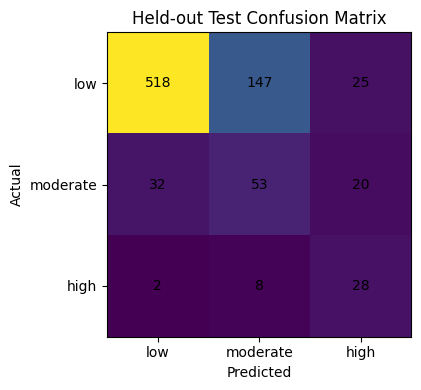

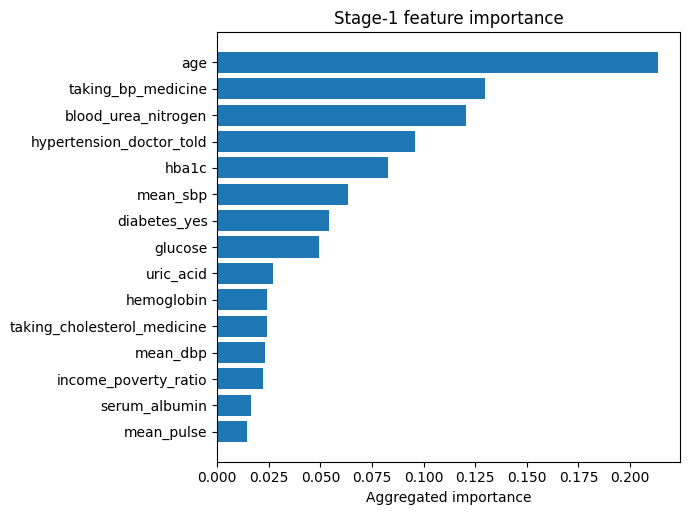

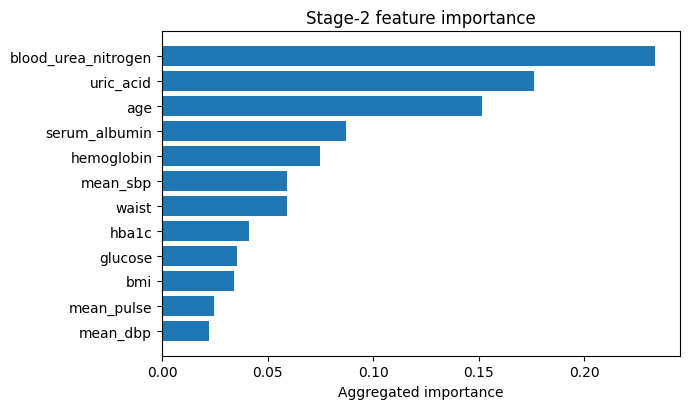

In [12]:
# ============================================================
# Cell 11: Simple plots
# ============================================================

if RUN_PLOTS:
    # Confusion matrix heatmap for test set.
    cm = cm_tables["test"]
    fig, ax = plt.subplots(figsize=(5, 4))
    im = ax.imshow(cm)
    ax.set_xticks(range(len(LABEL_ORDER)))
    ax.set_yticks(range(len(LABEL_ORDER)))
    ax.set_xticklabels(LABEL_ORDER)
    ax.set_yticklabels(LABEL_ORDER)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title("Held-out Test Confusion Matrix")
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center")
    fig.tight_layout()
    fig.savefig(PLOT_DIR / "test_confusion_matrix.png", dpi=200)
    plt.show()

    # Stage-1 and Stage-2 importance plots.
    for imp_df, title, fname in [
        (stage1_imp_df, "Stage-1 feature importance", "stage1_importance.png"),
        (stage2_imp_df, "Stage-2 feature importance", "stage2_importance.png"),
    ]:
        d = imp_df.head(15).iloc[::-1]
        fig, ax = plt.subplots(figsize=(7, max(4, len(d) * 0.35)))
        ax.barh(d["raw_feature"], d["importance"])
        ax.set_title(title)
        ax.set_xlabel("Aggregated importance")
        fig.tight_layout()
        fig.savefig(PLOT_DIR / fname, dpi=200)
        plt.show()
else:
    print("RUN_PLOTS is False; plots skipped.")


## Final decision summary

This cell prints the key test-set metrics that you should report for the final selected model.


In [13]:
# ============================================================
# Cell 12: Final decision summary for thesis/report
# ============================================================

test_row = metrics_df[metrics_df["split"] == "test"].iloc[0]
summary_table = pd.DataFrame([
    ["Accuracy", test_row.get("accuracy", np.nan)],
    ["Balanced accuracy", test_row.get("balanced_accuracy", np.nan)],
    ["Macro F1", test_row.get("macro_f1", np.nan)],
    ["Low recall", test_row.get("low_recall", np.nan)],
    ["Moderate recall", test_row.get("moderate_recall", np.nan)],
    ["High recall", test_row.get("high_recall", np.nan)],
    ["High → Low miss count", test_row.get("high_to_low_miss_count", np.nan)],
    ["Stage-1 threshold", test_row.get("stage1_threshold", STAGE1_THRESHOLD)],
    ["Stage-2 threshold", test_row.get("stage2_threshold", STAGE2_THRESHOLD)],
], columns=["Metric", "Value"])

print("Final selected model: baseline cascade + Stage-2 threshold 0.50")
display(summary_table.round(4))

print("\nReport-ready statement:")
print(
    "The final model uses a two-stage cascade: Stage-1 separates low-risk from at-risk participants "
    "using RF+RandomOverSampler, and Stage-2 separates moderate from high risk using OBU resampling, "
    "TreeMedian feature selection, and GradientBoosting. The Stage-2 threshold is fixed at 0.50 because "
    "it improved balanced accuracy and macro-F1 while preserving high-risk recall and the severe high-to-low miss count."
)


Final selected model: baseline cascade + Stage-2 threshold 0.50


,Metric,Value
0,Accuracy,0.7191
1,Balanced accuracy,0.6641
2,Macro F1,0.5591
3,Low recall,0.7507
4,Moderate recall,0.5048
5,High recall,0.7368
6,High → Low miss count,2.0000
7,Stage-1 threshold,0.4400
8,Stage-2 threshold,0.5000



Report-ready statement:
The final model uses a two-stage cascade: Stage-1 separates low-risk from at-risk participants using RF+RandomOverSampler, and Stage-2 separates moderate from high risk using OBU resampling, TreeMedian feature selection, and GradientBoosting. The Stage-2 threshold is fixed at 0.50 because it improved balanced accuracy and macro-F1 while preserving high-risk recall and the severe high-to-low miss count.


In [14]:
# ============================================================
# Cell 12: Save final model package and zip outputs
# ============================================================

package = {
    "model": final_model,
    "model_name": FINAL_MODEL_NAME,
    "description": FINAL_MODEL_DESCRIPTION,
    "label_order": LABEL_ORDER,
    "dataset_fix_version": DATASET_FIX_VERSION,
    "dataset_fix_notes": DATASET_FIX_NOTES,
    "model_features": ALL_FEATURES,
    "numeric_features": NUMERIC_FEATURES,
    "binary_features": BINARY_FEATURES,
    "excluded_from_model_columns": EXCLUDED_FROM_MODEL_COLUMNS,
    "stage1_selection_method": STAGE1_SELECTION_METHOD,
    "stage1_selected_k": STAGE1_SELECTED_K,
    "stage1_features": stage1_features,
    "stage1_threshold": STAGE1_THRESHOLD,
    "stage1_config": FINAL_STAGE1_CONFIG,
    "stage2_selection_method": STAGE2_SELECTION_METHOD,
    "stage2_input_k": STAGE2_INPUT_K,
    "stage2_input_features": stage2_input_features,
    "stage2_selected_features": stage2_selected_features,
    "stage2_threshold": STAGE2_THRESHOLD,
    "stage2_config": FIXED_STAGE2_CONFIG,
    "metrics": metrics_df,
    "target_distribution": target_dist,
}

if SAVE_MODEL_PACKAGE and JOBLIB_AVAILABLE:
    package_path = MODEL_DIR / "joint_s1_rfbalanced_k19_s2_rfbalanced_k12_stage2_thr050_model_package.joblib"
    joblib.dump(package, package_path)
    print("Saved model package:", package_path)
else:
    print("Model package not saved. SAVE_MODEL_PACKAGE or JOBLIB_AVAILABLE is False.")

# Save lightweight config as JSON.
config_json = {
    "model_name": FINAL_MODEL_NAME,
    "description": FINAL_MODEL_DESCRIPTION,
    "dataset_fix_version": DATASET_FIX_VERSION,
    "stage1_selection_method": STAGE1_SELECTION_METHOD,
    "stage1_selected_k": STAGE1_SELECTED_K,
    "stage1_features": stage1_features,
    "stage1_threshold": STAGE1_THRESHOLD,
    "stage2_selection_method": STAGE2_SELECTION_METHOD,
    "stage2_input_k": STAGE2_INPUT_K,
    "stage2_input_features": stage2_input_features,
    "stage2_selected_features": stage2_selected_features,
    "stage2_threshold": STAGE2_THRESHOLD,
    "stage2_config": FIXED_STAGE2_CONFIG,
}
with open(MODEL_DIR / "model_config.json", "w") as f:
    json.dump(config_json, f, indent=2)

# Zip outputs for easy download.
zip_path = shutil.make_archive(str(OUTPUT_DIR), "zip", root_dir=OUTPUT_DIR)
print("Zipped outputs:", zip_path)
print("Done.")


Saved model package: /content/nhanes_FINAL_CLEAR_STAGE2_THR050_outputs/model_package/joint_s1_rfbalanced_k19_s2_rfbalanced_k12_stage2_thr050_model_package.joblib
Zipped outputs: /content/nhanes_FINAL_CLEAR_STAGE2_THR050_outputs.zip
Done.
